In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Convert data into DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df['target'] = cancer.target

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nTarget Classes:")
print(cancer.target_names)


Dataset Shape: (569, 31)

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst

In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['target'].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

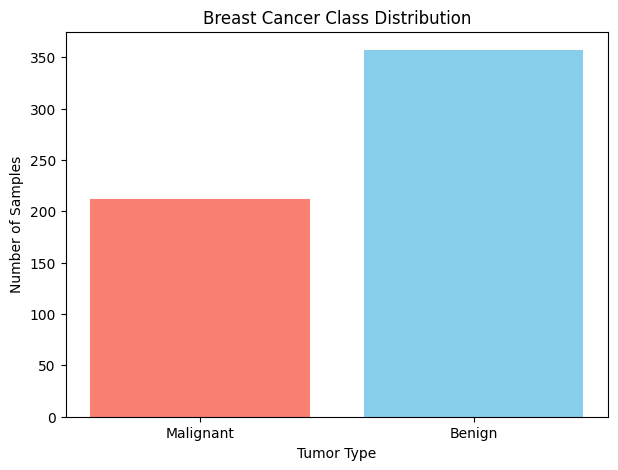

In [4]:

# Count benign and malignant samples
class_counts = df['target'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ['Malignant', 'Benign'],
    class_counts.values,
    color=['salmon', 'skyblue']
)

plt.title('Breast Cancer Class Distribution')
plt.xlabel('Tumor Type')
plt.ylabel('Number of Samples')
plt.show()


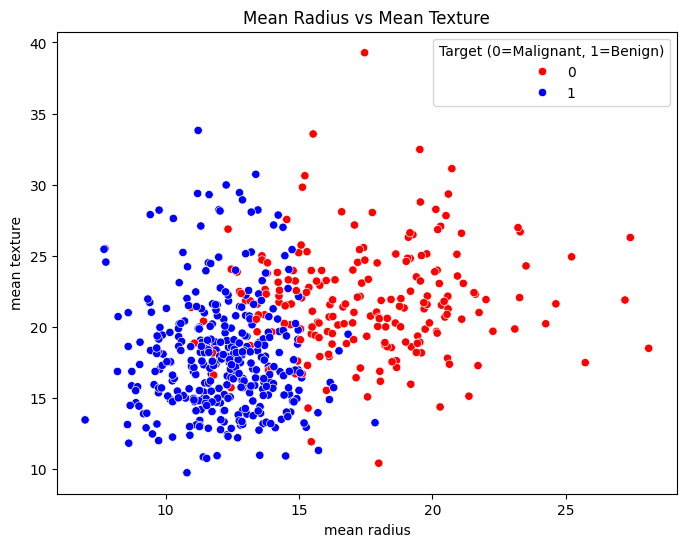

In [5]:

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='mean radius',
    y='mean texture',
    hue='target',
    palette={0: 'red', 1: 'blue'}
)

plt.title('Mean Radius vs Mean Texture')
plt.legend(title='Target (0=Malignant, 1=Benign)')
plt.show()


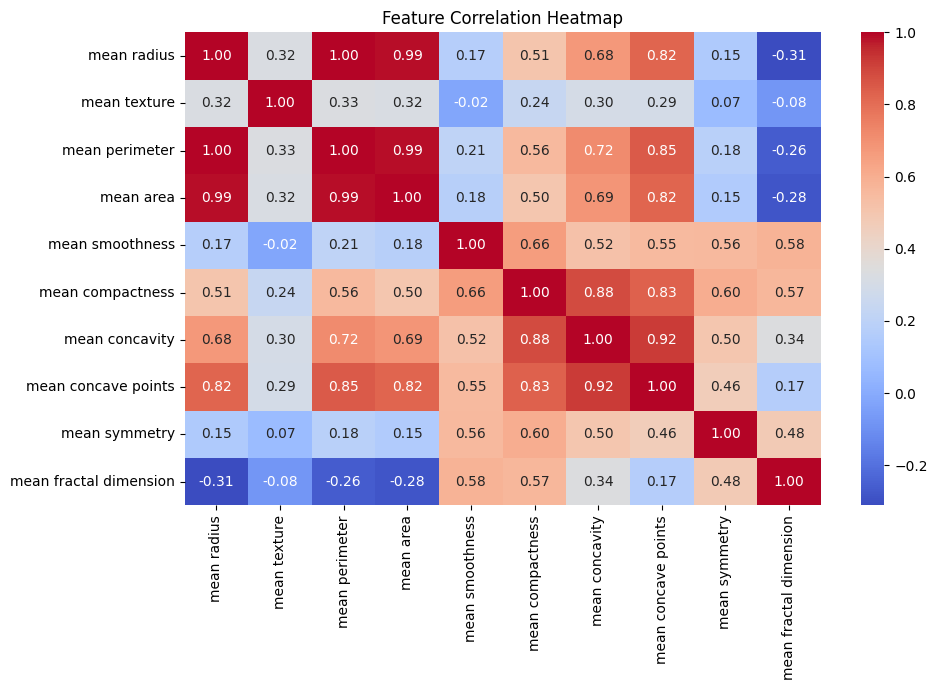

In [6]:

# Select 10 features for a readable heatmap
features = df.columns[:10]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [7]:

# Separate input features and target
X = df.drop('target', axis=1)
y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (569, 30)
Target Shape: (569,)


In [8]:

from sklearn.model_selection import train_test_split

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (455, 30)
Testing Data: (114, 30)


In [9]:

from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply same transformation to testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nFirst 5 scaled values:")
print(X_train_scaled[0][:5])


Feature scaling completed!

First 5 scaled values:
[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988]


In [10]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Define three classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "SVM": SVC(
        kernel='rbf', probability=True, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

# Train and evaluate each model
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    trained_models[name] = model

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    print(f"{name}: {accuracy * 100:.2f}%")


Logistic Regression: 98.25%
SVM: 98.25%
Random Forest: 95.61%


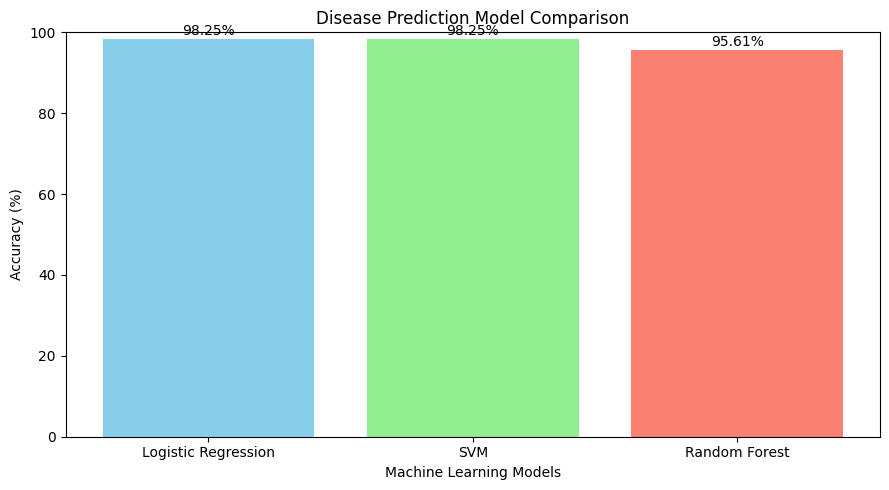

In [11]:

import matplotlib.pyplot as plt

model_names = []
accuracies = []

for name, model in trained_models.items():
    predictions = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, predictions)

    model_names.append(name)
    accuracies.append(accuracy * 100)

plt.figure(figsize=(9, 5))

plt.bar(model_names, accuracies,
        color=['skyblue', 'lightgreen', 'salmon'])

plt.title("Disease Prediction Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f"{acc:.2f}%", ha='center')

plt.tight_layout()
plt.show()


In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)

    # Probability of malignant class (class 0)
    malignant_index = list(model.classes_).index(0)
    y_prob = model.predict_proba(
        X_test_scaled
    )[:, malignant_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == 0).astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.9825     0.9762  0.9762    0.9762   0.9954
                SVM    0.9825     0.9762  0.9762    0.9762   0.9950
      Random Forest    0.9561     0.9512  0.9286    0.9398   0.9939


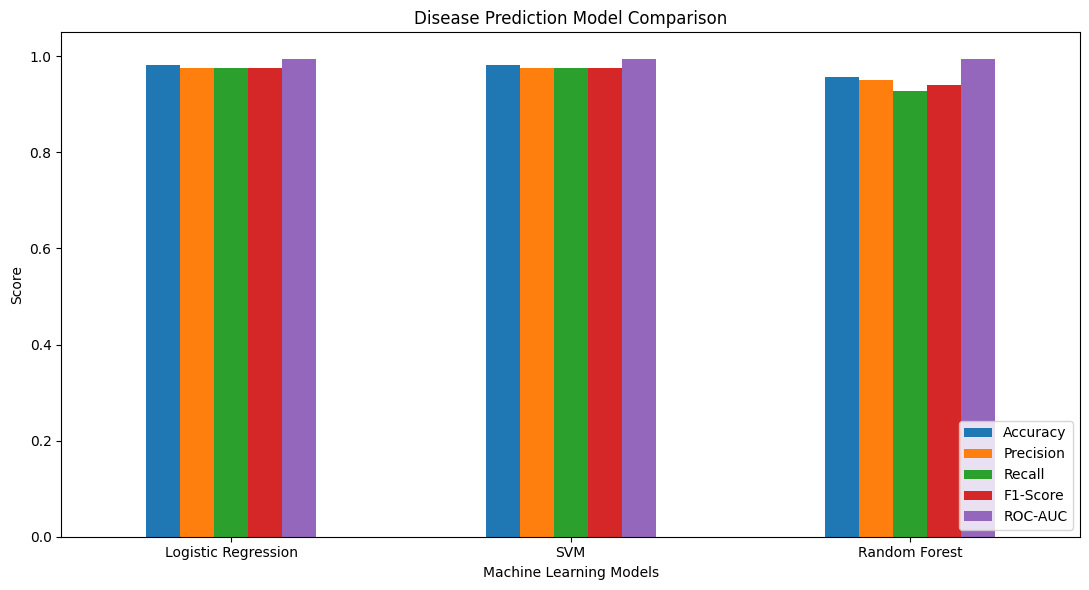

In [13]:

import matplotlib.pyplot as plt

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Disease Prediction Model Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


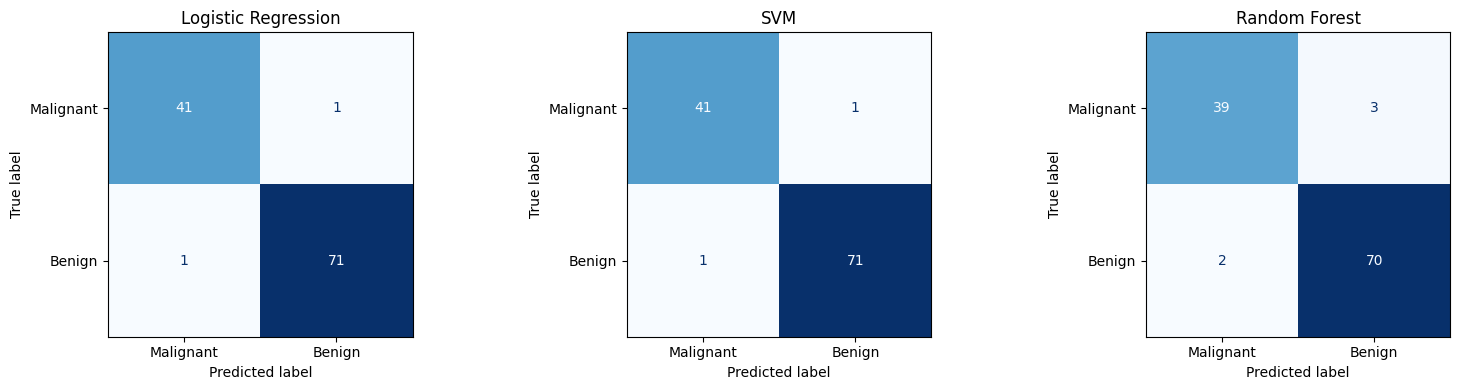

In [14]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(
    axes, trained_models.items()
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test_scaled,
        y_test,
        labels=[0, 1],
        display_labels=["Malignant", "Benign"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [15]:

# Select best model
best_model = trained_models["Logistic Regression"]

# Select one test sample
sample = X_test.iloc[[0]]
actual = y_test.iloc[0]

# Apply feature scaling
sample_scaled = scaler.transform(sample)

# Make prediction
prediction = best_model.predict(sample_scaled)[0]

print("Actual Class:",
      "Malignant" if actual == 0 else "Benign")

print("Predicted Class:",
      "Malignant" if prediction == 0 else "Benign")


Actual Class: Malignant
Predicted Class: Malignant


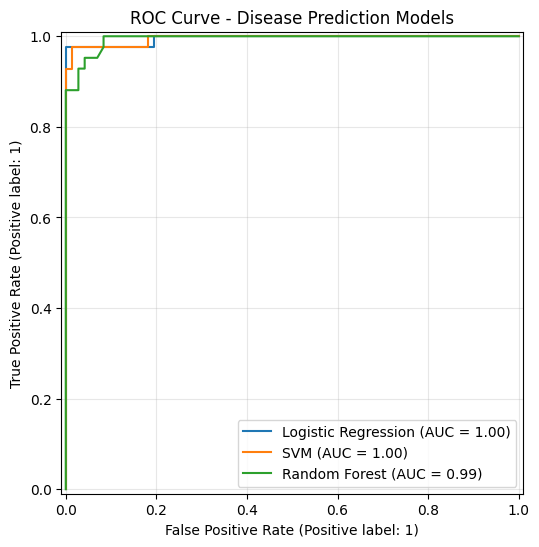

In [16]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Convert malignant into positive class
y_test_binary = (y_test == 0).astype(int)

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in trained_models.items():

    # Get probability of malignant class
    malignant_index = list(model.classes_).index(0)
    y_prob = model.predict_proba(
        X_test_scaled
    )[:, malignant_index]

    RocCurveDisplay.from_predictions(
        y_test_binary,
        y_prob,
        name=name,
        ax=ax
    )

plt.title("ROC Curve - Disease Prediction Models")
plt.grid(alpha=0.3)
plt.show()


In [17]:

import joblib

# Save model and scaler together
joblib.dump({
    "model": best_model,
    "scaler": scaler,
    "feature_names": X.columns.tolist()
}, "disease_prediction_model.pkl")

print("Model saved successfully!")


Model saved successfully!
